In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
SRC = "/content/drive/MyDrive/AI_Cheema_Gang/GeneratedLabelledFlows/TrafficLabelling"
!ls -la "{SRC}"

total 1174918
drwx------ 2 root root      4096 Oct  3 13:50 .
drwx------ 3 root root      4096 Oct  3 13:50 ..
-rw------- 1 root root  96101069 Oct  3 13:48 Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
-rw------- 1 root root 101874777 Oct  3 13:48 Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
-rw------- 1 root root  75386737 Oct  3 13:48 Friday-WorkingHours-Morning.pcap_ISCX.csv
-rw------- 1 root root 268649908 Oct  3 13:48 Monday-WorkingHours.pcap_ISCX.csv
-rw------- 1 root root 108723183 Oct  3 13:48 Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
-rw------- 1 root root  92030223 Oct  3 13:48 Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
-rw------- 1 root root 174696560 Oct  3 13:48 Tuesday-WorkingHours.pcap_ISCX.csv
-rw------- 1 root root 285642925 Oct  3 13:48 Wednesday-workingHours.pcap_ISCX.csv


In [10]:
!mkdir -p /content/data
!cp -rLv "{SRC}" /content/data/
!ls -lh /content/data/TrafficLabelling/

'/content/drive/MyDrive/AI_Cheema_Gang/GeneratedLabelledFlows/TrafficLabelling' -> '/content/data/TrafficLabelling'
'/content/drive/MyDrive/AI_Cheema_Gang/GeneratedLabelledFlows/TrafficLabelling/Wednesday-workingHours.pcap_ISCX.csv' -> '/content/data/TrafficLabelling/Wednesday-workingHours.pcap_ISCX.csv'
'/content/drive/MyDrive/AI_Cheema_Gang/GeneratedLabelledFlows/TrafficLabelling/Tuesday-WorkingHours.pcap_ISCX.csv' -> '/content/data/TrafficLabelling/Tuesday-WorkingHours.pcap_ISCX.csv'
'/content/drive/MyDrive/AI_Cheema_Gang/GeneratedLabelledFlows/TrafficLabelling/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv' -> '/content/data/TrafficLabelling/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv'
'/content/drive/MyDrive/AI_Cheema_Gang/GeneratedLabelledFlows/TrafficLabelling/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv' -> '/content/data/TrafficLabelling/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv'
'/content/drive/MyDrive/AI_Cheema_Gang/Generat

In [34]:
import os, gc, glob
import numpy as np
import pandas as pd

RAW_DIR     = "/content/data/TrafficLabelling"
OUT_DIR     = "/content/drive/MyDrive/AI_Cheema_Gang/processed"
INTERIM_DIR = os.path.join(OUT_DIR, "per_day")

META_COLS = ["Flow ID", "Source IP", "Source Port",
             "Destination IP", "Destination Port", "Protocol", "Timestamp"]
EXCLUDE_FROM_DEDUP = ["Flow ID", "Timestamp", "day", "day_order"]

LABEL_COL = "Label"

DAY_MAP = {"Monday": ("Monday", 1), "Tuesday": ("Tuesday", 2),
           "Wednesday": ("Wednesday", 3), "Thursday": ("Thursday", 4),
           "Friday": ("Friday", 5)}

KNOWN_DUPLICATE_COLS = ["Fwd Header Length.1"]

os.makedirs(INTERIM_DIR, exist_ok=True)
csvs = sorted(glob.glob(os.path.join(RAW_DIR, "*.csv")))
print(f"{len(csvs)} files found, output -> {OUT_DIR}")

8 files found, output -> /content/drive/MyDrive/AI_Cheema_Gang/processed


In [35]:
class CleaningLog:

    def __init__(self):
        self.rows = []

    def add(self, day, step, before, after, detail=""):
        self.rows.append({"day": day, "step": step,
                          "rows_before": before, "rows_after": after,
                          "rows_removed": before - after, "detail": detail})
        removed = before - after
        pct = (removed / before * 100) if before else 0
        print(f"    {step:<28} {before:>9,} -> {after:>9,}  "
              f"({removed:,} removed, {pct:.3f}%)  {detail}")

    def to_frame(self):
        return pd.DataFrame(self.rows)

LOG = CleaningLog()

Helpers

In [36]:
def identify_day(filename):
    base = os.path.basename(filename)
    for key, (day, order) in DAY_MAP.items():
        if key.lower() in base.lower():
            return day, order
    raise ValueError(f"Could not determine day for: {base}")


def normalise_label(value):

    if not isinstance(value, str):
        return value
    v = value.replace("\x96", "-").replace("\u2013", "-").replace("\u2011", "-")
    return " ".join(v.split()).strip()


def fix_12_hour_clock(ts, day="?"):

    hours = ts.dt.hour
    if hours.max() > 12:
        print(f"    timestamps: {day} already 24-hour, left unchanged")
        return ts
    needs_shift = hours.between(1, 7)
    n = int(needs_shift.sum())
    ts = ts + pd.to_timedelta(needs_shift.astype(int) * 12, unit="h")
    print(f"    timestamps: +12h applied to {n:,} afternoon rows  "
          f"(range now {ts.min().strftime('%H:%M')} - {ts.max().strftime('%H:%M')})")
    return ts


def downcast(df):
    for col in df.select_dtypes(include=["float64"]).columns:
        df[col] = df[col].astype("float32")
    for col in df.select_dtypes(include=["int64"]).columns:
        c_min, c_max = df[col].min(), df[col].max()
        if c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
            df[col] = df[col].astype("int32")
    return df


def mem_mb(df):
    return df.memory_usage(deep=True).sum() / 1024 ** 2

Per-day cleaning

In [37]:
def clean_one_day(path):
    day, day_order = identify_day(path)
    print(f"\n{'='*70}\n{day}  |  {os.path.basename(path)}\n{'='*70}")

    df = pd.read_csv(path, encoding="latin1", low_memory=False)
    n0 = len(df)
    print(f"    loaded: {n0:,} rows x {df.shape[1]} cols  ({mem_mb(df):.0f} MB)")

    df.columns = [c.strip() for c in df.columns]

    unnamed = [c for c in df.columns if c.startswith("Unnamed")]
    if unnamed:
        df = df.drop(columns=unnamed)
        print(f"    dropped unnamed columns: {unnamed}")

    before = len(df)
    df = df.dropna(how="all")
    df = df[df[LABEL_COL].notna()]
    if len(df) < before:
        LOG.add(day, "fully empty rows", before, len(df),
                "blank padding lines at end of CSV")

    df["day"] = day
    df["day_order"] = day_order
    df[LABEL_COL] = df[LABEL_COL].apply(normalise_label)

    before = len(df)
    df = df[df[LABEL_COL] != LABEL_COL]
    if len(df) < before:
        LOG.add(day, "repeated header rows", before, len(df))

    if "Timestamp" in df.columns:
        df["Timestamp"] = pd.to_datetime(df["Timestamp"], dayfirst=True,
                                         errors="coerce")
        n_bad = int(df["Timestamp"].isna().sum())
        if n_bad:
            print(f"    warning: {n_bad:,} timestamps failed to parse")
        df["Timestamp"] = fix_12_hour_clock(df["Timestamp"], day)

    dupes = [c for c in KNOWN_DUPLICATE_COLS if c in df.columns]
    if dupes:
        df = df.drop(columns=dupes)
        print(f"    dropped duplicate column(s): {dupes}")

    feature_cols = [c for c in df.columns
                    if c not in META_COLS + [LABEL_COL, "day", "day_order"]]
    for col in feature_cols:
        if df[col].dtype == object:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    inf_counts = {}
    for col in feature_cols:
        if pd.api.types.is_numeric_dtype(df[col]):
            n_inf = int(np.isinf(df[col]).sum())
            if n_inf:
                inf_counts[col] = n_inf
                df[col] = df[col].replace([np.inf, -np.inf], np.nan)
    if inf_counts:
        print(f"    infinities -> NaN: {sum(inf_counts.values()):,} values  {inf_counts}")

    before = len(df)
    null_by_col = df[feature_cols].isna().sum()
    null_by_col = null_by_col[null_by_col > 0].to_dict()
    df = df.dropna(subset=feature_cols)
    if before != len(df):
        LOG.add(day, "rows with missing features", before, len(df),
                f"columns affected: {null_by_col}")

    before = len(df)
    dedup_on = [c for c in df.columns if c not in EXCLUDE_FROM_DEDUP]
    df = df.drop_duplicates(subset=dedup_on, keep="first")
    LOG.add(day, "exact duplicate flows", before, len(df))

    df = downcast(df).reset_index(drop=True)
    LOG.add(day, "TOTAL for day", n0, len(df))
    print(f"    final: {len(df):,} rows x {df.shape[1]} cols  ({mem_mb(df):.0f} MB)")
    print(f"    labels: {df[LABEL_COL].value_counts().to_dict()}")
    return df

Run the per-day loop

In [38]:
for path in csvs:
    d = clean_one_day(path)
    out = os.path.join(INTERIM_DIR,
                       os.path.basename(path).replace(".csv", "") + ".parquet")
    d.to_parquet(out, index=False)
    del d
    gc.collect()

print("\nper-day cleaning complete")


Friday  |  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
    loaded: 225,745 rows x 85 cols  (207 MB)
    timestamps: +12h applied to 225,745 afternoon rows  (range now 15:30 - 17:02)
    dropped duplicate column(s): ['Fwd Header Length.1']
    infinities -> NaN: 64 values  {'Flow Bytes/s': 30, 'Flow Packets/s': 34}
    rows with missing features     225,745 ->   225,711  (34 removed, 0.015%)  columns affected: {'Flow Bytes/s': 34, 'Flow Packets/s': 34}
    exact duplicate flows          225,711 ->   225,628  (83 removed, 0.037%)  
    TOTAL for day                  225,745 ->   225,628  (117 removed, 0.052%)  
    final: 225,628 rows x 86 cols  (138 MB)
    labels: {'DDoS': 128025, 'BENIGN': 97603}

Friday  |  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
    loaded: 286,467 rows x 85 cols  (264 MB)
    timestamps: +12h applied to 286,467 afternoon rows  (range now 13:00 - 15:29)
    dropped duplicate column(s): ['Fwd Header Length.1']
    infinities -> NaN: 727 values  {'F

Merge

In [39]:
def merge_days(interim_dir):
    print(f"\n{'='*70}\nMERGE\n{'='*70}")
    files = sorted(glob.glob(os.path.join(interim_dir, "*.parquet")))
    if not files:
        raise FileNotFoundError(f"No per-day parquet files in {interim_dir}")

    parts = []
    for f in files:
        part = pd.read_parquet(f)
        print(f"    + {os.path.basename(f)[:50]:<53} {len(part):>9,} rows")
        parts.append(part)

    df = pd.concat(parts, ignore_index=True)
    del parts; gc.collect()

    n0 = len(df)
    print(f"    merged: {n0:,} rows x {df.shape[1]} cols  ({mem_mb(df):.0f} MB)")

    feature_cols = [c for c in df.columns
                    if c not in META_COLS + [LABEL_COL, "day", "day_order"]]

    nunique = df[feature_cols].nunique()
    constant = nunique[nunique <= 1].index.tolist()
    if constant:
        df = df.drop(columns=constant)
        feature_cols = [c for c in feature_cols if c not in constant]
        print(f"    dropped {len(constant)} constant columns: {constant}")

    before = len(df)
    dedup_on = [c for c in df.columns if c not in EXCLUDE_FROM_DEDUP]
    df = df.drop_duplicates(subset=dedup_on, keep="first")
    LOG.add("ALL", "cross-day duplicate flows", before, len(df))

    df["label_binary"] = (df[LABEL_COL] != "BENIGN").astype("int8")

    if "Timestamp" in df.columns:
        df = df.sort_values(["day_order", "Timestamp"]).reset_index(drop=True)
    else:
        df = df.sort_values("day_order").reset_index(drop=True)

    LOG.add("ALL", "TOTAL merged", n0, len(df))
    return df, feature_cols


df, feature_cols = merge_days(INTERIM_DIR)


MERGE
    + Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.parqu      225,628 rows
    + Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.p      285,930 rows
    + Friday-WorkingHours-Morning.pcap_ISCX.parquet           190,566 rows
    + Monday-WorkingHours.pcap_ISCX.parquet                   528,681 rows
    + Thursday-WorkingHours-Afternoon-Infilteration.pcap      287,932 rows
    + Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX      169,925 rows
    + Tuesday-WorkingHours.pcap_ISCX.parquet                  444,811 rows
    + Wednesday-workingHours.pcap_ISCX.parquet                682,922 rows
    merged: 2,816,395 rows x 86 cols  (2333 MB)
    dropped 8 constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
    cross-day duplicate flows    2,816,395 -> 2,814,572  (1,823 removed, 0.065%)  
    TOTAL merged                 2,816,395 -> 2,814,572  (1,8

Save

In [40]:
merged_path = os.path.join(OUT_DIR, "cicids2017_clean.parquet")
df.to_parquet(merged_path, index=False)
print(f"saved -> {merged_path}  ({os.path.getsize(merged_path)/1024**2:.0f} MB)")

log_df = LOG.to_frame()
log_df.to_csv(os.path.join(OUT_DIR, "cleaning_log.csv"), index=False)

pd.Series(feature_cols).to_csv(os.path.join(OUT_DIR, "feature_columns.csv"),
                               index=False, header=["feature"])
print("saved cleaning log and feature list")

saved -> /content/drive/MyDrive/AI_Cheema_Gang/processed/cicids2017_clean.parquet  (295 MB)
saved cleaning log and feature list


Summary

In [41]:
print(f"rows: {len(df):,}   features: {len(feature_cols)}   memory: {mem_mb(df):.0f} MB\n")

print("Class distribution")
print("-"*70)
vc = df[LABEL_COL].value_counts()
for label, n in vc.items():
    print(f"  {label:<32} {n:>10,}   {n/len(df)*100:>7.4f}%")
print(f"\n  imbalance ratio = {vc.max()/vc.min():,.0f} : 1")

print("\nRows per day")
print("-"*70)
for day, n in df.groupby("day", sort=False).size().items():
    print(f"  {day:<12} {n:>10,}")

n_all = pd.concat([df["Source IP"], df["Destination IP"]]).nunique()
print("\nGraph viability")
print("-"*70)
print(f"  unique IPs (nodes) : {n_all:,}")
print(f"  flows     (edges)  : {len(df):,}")
print(f"  avg edges per node : {len(df)/n_all:.1f}")

print(f"\n{'='*70}\nCLEANING LOG\n{'='*70}")
print(LOG.to_frame().to_string(index=False))

rows: 2,814,572   features: 68   memory: 2162 MB

Class distribution
----------------------------------------------------------------------
  BENIGN                            2,265,604   80.4955%
  DoS Hulk                            222,563    7.9075%
  PortScan                            158,804    5.6422%
  DDoS                                128,025    4.5486%
  DoS GoldenEye                        10,293    0.3657%
  FTP-Patator                           7,935    0.2819%
  SSH-Patator                           5,897    0.2095%
  DoS slowloris                         5,769    0.2050%
  DoS Slowhttptest                      5,499    0.1954%
  Bot                                   1,956    0.0695%
  Web Attack - Brute Force              1,507    0.0535%
  Web Attack - XSS                        652    0.0232%
  Infiltration                             36    0.0013%
  Web Attack - Sql Injection               21    0.0007%
  Heartbleed                               11    0.0004%

  im

##**PREPROCESSING**

In [42]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

C = ["#3B6FD4", "#D4663B", "#8A5BBF", "#4F9D69"]
INK, MUTED, GRID = "#1a1a19", "#5c5c58", "#e4e4e0"

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
})

def save(fig, name):
    p = os.path.join(FIG_DIR, name)
    fig.savefig(p)
    print("saved", p)

print(f"{len(df):,} rows ready")

2,814,572 rows ready


saved /content/drive/MyDrive/AI_Cheema_Gang/processed/figures/01_class_distribution.png


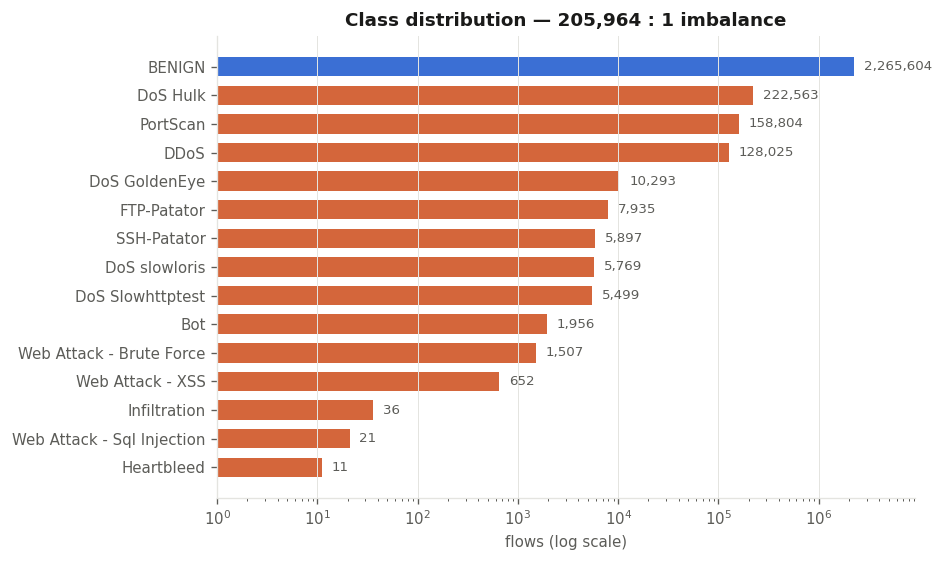

In [43]:
vc = df["Label"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7.5, 5))
bars = ax.barh(vc.index, vc.values, height=0.68,
               color=[C[0] if l == "BENIGN" else C[1] for l in vc.index])
ax.set_xscale("log")
ax.set_xlim(1, vc.max() * 4)
ax.set_xlabel("flows (log scale)")
ax.set_title("Class distribution — 205,964 : 1 imbalance")
ax.grid(axis="y", visible=False)

for b, v in zip(bars, vc.values):
    ax.text(v * 1.25, b.get_y() + b.get_height()/2, f"{v:,}",
            va="center", fontsize=8, color=MUTED)

save(fig, "01_class_distribution.png")
plt.show()

saved /content/drive/MyDrive/AI_Cheema_Gang/processed/figures/02_traffic_over_time.png


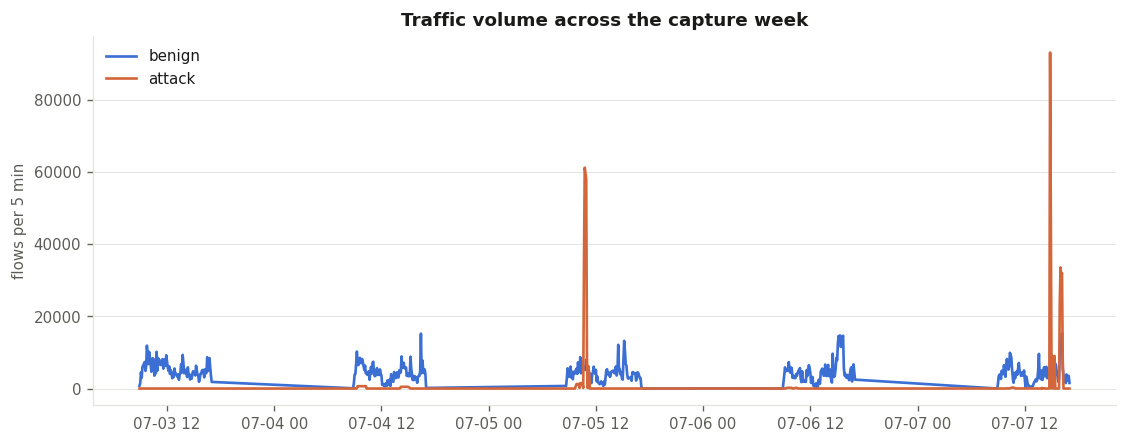

In [44]:
t = df.set_index("Timestamp")
bins = t.resample("5min")["label_binary"].agg(["size", "sum"])
bins = bins[bins["size"] > 0]
bins["benign"] = bins["size"] - bins["sum"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(bins.index, bins["benign"], lw=1.6, color=C[0], label="benign")
ax.plot(bins.index, bins["sum"], lw=1.6, color=C[1], label="attack")
ax.set_ylabel("flows per 5 min")
ax.set_title("Traffic volume across the capture week")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)

save(fig, "02_traffic_over_time.png")
plt.show()

pairs with |r| > 0.95: 38
saved /content/drive/MyDrive/AI_Cheema_Gang/processed/figures/03_correlation.png


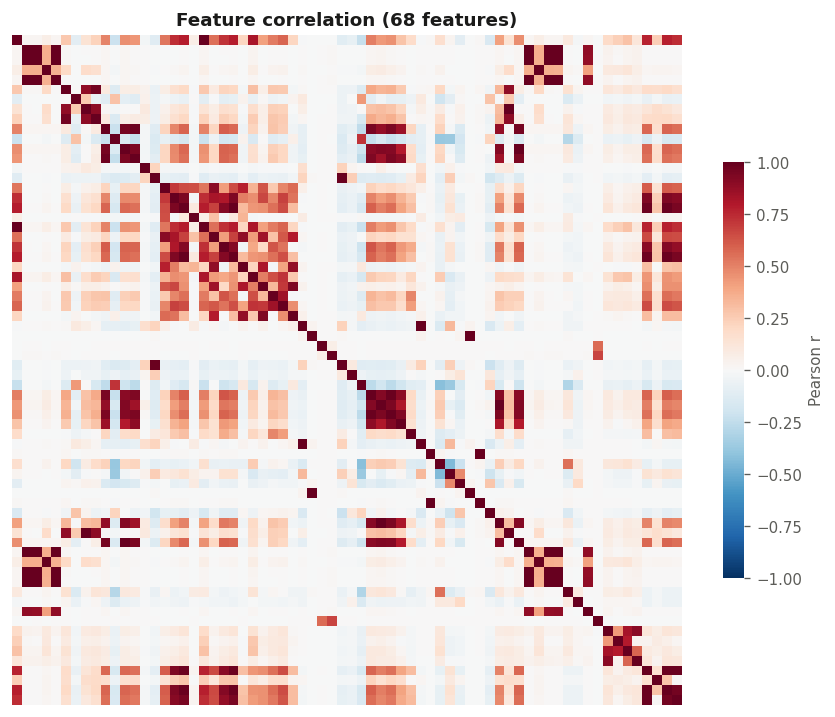

In [45]:
corr = df[feature_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False, square=True,
            cbar_kws={"shrink": 0.6, "label": "Pearson r"}, ax=ax)
ax.set_title(f"Feature correlation ({len(feature_cols)} features)")

high = (corr.abs() > 0.95).sum().sum() - len(corr)
print(f"pairs with |r| > 0.95: {high // 2}")

save(fig, "03_correlation.png")
plt.show()

saved /content/drive/MyDrive/AI_Cheema_Gang/processed/figures/04_feature_separation.png


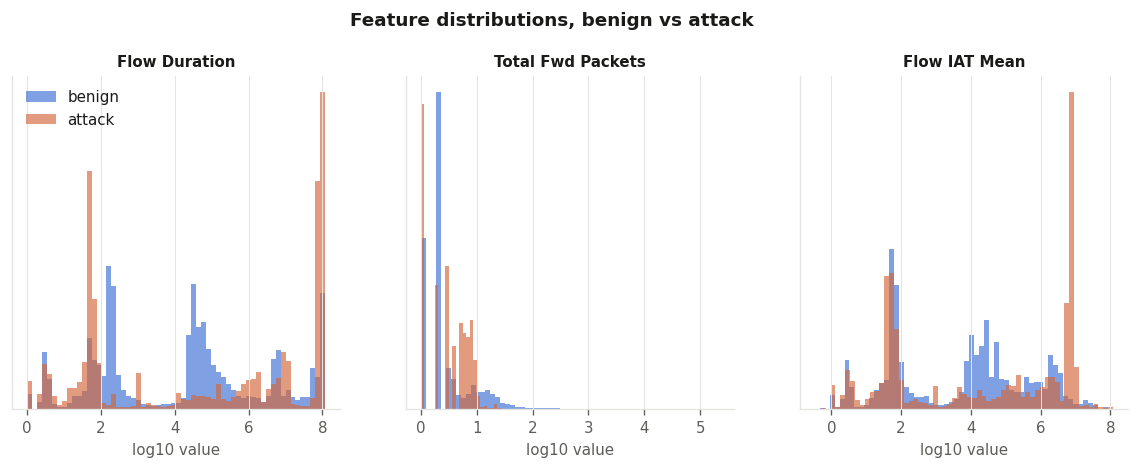

In [46]:
feats = ["Flow Duration", "Total Fwd Packets", "Flow IAT Mean"]
feats = [f for f in feats if f in df.columns][:3]

fig, axes = plt.subplots(1, len(feats), figsize=(4*len(feats), 3.6))
for ax, f in zip(np.atleast_1d(axes), feats):
    for i, (name, mask) in enumerate([("benign", df.label_binary == 0),
                                      ("attack", df.label_binary == 1)]):
        v = df.loc[mask, f]
        v = v[v > 0]
        ax.hist(np.log10(v), bins=60, alpha=0.65, color=C[i],
                label=name, density=True)
    ax.set_title(f, fontsize=9)
    ax.set_xlabel("log10 value")
    ax.set_yticks([])
np.atleast_1d(axes)[0].legend(frameon=False)
fig.suptitle("Feature distributions, benign vs attack", y=1.03,
             fontsize=11, fontweight="bold")

save(fig, "04_feature_separation.png")
plt.show()

saved /content/drive/MyDrive/AI_Cheema_Gang/processed/figures/05_graph_structure.png


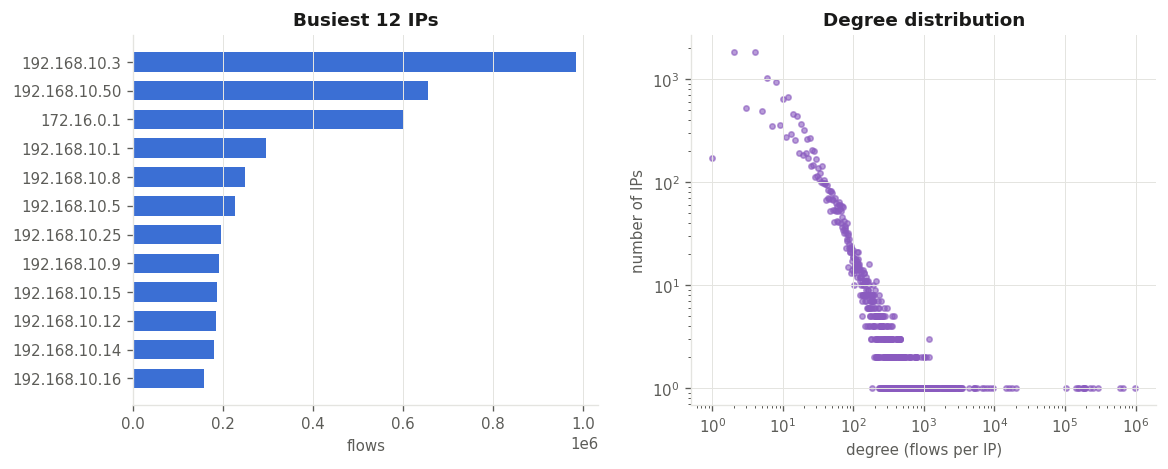

nodes           : 19,129
edges           : 2,814,572
mean degree     : 294.3
median degree   : 14
max degree      : 983,910  (192.168.10.3)


In [47]:
deg = pd.concat([df["Source IP"], df["Destination IP"]]).value_counts()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))

top = deg.head(12).sort_values()
a1.barh(top.index, top.values, height=0.68, color=C[0])
a1.set_xlabel("flows")
a1.set_title("Busiest 12 IPs")
a1.grid(axis="y", visible=False)

counts = deg.value_counts().sort_index()
a2.scatter(counts.index, counts.values, s=10, color=C[2], alpha=0.6)
a2.set_xscale("log"); a2.set_yscale("log")
a2.set_xlabel("degree (flows per IP)"); a2.set_ylabel("number of IPs")
a2.set_title("Degree distribution")

save(fig, "05_graph_structure.png")
plt.show()

print(f"nodes           : {deg.size:,}")
print(f"edges           : {len(df):,}")
print(f"mean degree     : {deg.mean():.1f}")
print(f"median degree   : {deg.median():.0f}")
print(f"max degree      : {deg.max():,}  ({deg.idxmax()})")